# Hand Gesture Recognition from a Self-Collected Dataset

**Computer Vision — Assignment 1**

Three static hand gestures — **fist**, **peace** (V-sign) and **thumb** (thumbs-up) —
are recognised from images extracted from video I recorded myself.

The notebook runs end to end:

1. building the image dataset from raw `.MOV` recordings
2. exploring it, and splitting it **by recording** so that no clip appears on both sides of the split
3. preprocessing and augmentation
4. three baselines (Logistic Regression, SVM on HOG, a small CNN trained from scratch)
5. an improved model (ResNet-18 transfer learning)
6. evaluation: accuracy, precision, recall, F1, confusion matrices, error analysis

In [1]:
%matplotlib inline

import json
import os
import random
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import LeaveOneGroupOut, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from skimage.feature import hog
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "dataset"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FAST = os.environ.get("FAST_MODE") == "1"  # shortens training while debugging

print("torch", torch.__version__, "| device:", DEVICE, "| fast mode:", FAST)

torch 2.14.0+cpu | device: cpu | fast mode: False


## 1. Dataset collection

### How the raw data was recorded

I recorded **11 videos** on a phone (1072x1920 portrait, 60 fps, 12-26 s each).
The recording plan was a small grid over the three factors I could control:

| factor | levels |
|---|---|
| gesture | fist, peace, thumb |
| take (background / hand pose set) | take 1, take 2 |
| lighting | normal, dark |

That is 3 x 2 x 2 = 12 clips; `thumb2_dark` was not recorded, so there are 11.
Within each clip I continuously rotated and translated the hand so that a single
take covers many viewpoints rather than one frozen pose.

### From video to images

`build_dataset.py` samples frames at a uniform stride (dropping the first and
last 5% of each clip, where the hand is still moving into position), centre-crops
each frame to a square and resizes to 224x224. The hand is roughly centred in
every clip, so a centre crop keeps it fully in frame while removing the
distortion a direct 1072x1920 -> square resize would introduce.

`thumb` has one clip fewer, so it is sampled more densely (80 frames/clip vs 60)
to keep the classes **exactly balanced at 240 images each — 720 in total**.

In [2]:
# The extraction step (already run; see build_dataset.py for the full script).
# Re-run it from the notebook with:  !python build_dataset.py

meta = pd.read_csv(os.path.join(DATA_DIR, "metadata.csv"))
CLASSES = sorted(meta["label"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

print(f"{len(meta)} images, classes: {CLASSES}")
meta.head()

720 images, classes: ['fist', 'peace', 'thumb']


,filepath,label,video,take,lighting,frame_index,position_in_take,split
0,fist/fist1_f00053.jpg,fist,fist1,1,normal,53,0.0000,trainval
1,fist/fist1_f00069.jpg,fist,fist1,1,normal,69,0.0166,trainval
2,fist/fist1_f00085.jpg,fist,fist1,1,normal,85,0.0333,trainval
3,fist/fist1_f00101.jpg,fist,fist1,1,normal,101,0.0499,trainval
4,fist/fist1_f00117.jpg,fist,fist1,1,normal,117,0.0666,trainval


In [3]:
print("images per class:")
print(meta["label"].value_counts().sort_index(), "\n")
print("images per (class, lighting):")
print(meta.pivot_table(index="label", columns="lighting", values="filepath", aggfunc="count"), "\n")
print("images per clip:")
print(meta.groupby(["label", "video"]).size())

images per class:
label
fist     240
peace    240
thumb    240
Name: count, dtype: int64 

images per (class, lighting):
lighting  dark  normal
label                 
fist       120     120
peace      120     120
thumb       80     160 

images per clip:
label  video      
fist   fist1          60
       fist1_dark     60
       fist2          60
       fist2_dark     60
peace  peace1         60
       peace1_dark    60
       peace2         60
       peace2_dark    60
thumb  thumb1         80
       thumb1_dark    80
       thumb2         80
dtype: int64


## 2. Exploratory analysis

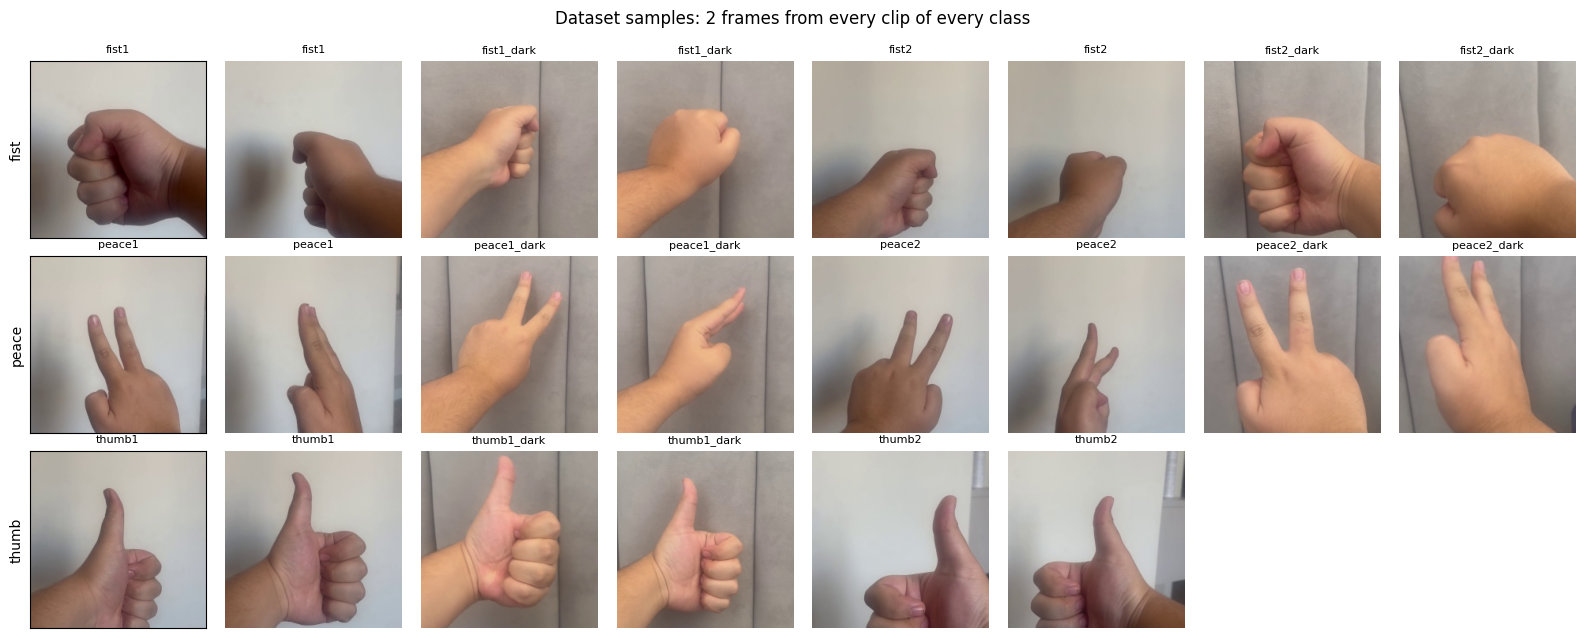

In [4]:
def imread_unicode(path, flags=cv2.IMREAD_COLOR):
    """cv2.imread cannot open non-ASCII paths on Windows (this project lives under a
    Cyrillic folder name), so read the bytes ourselves and decode them."""
    buf = np.fromfile(path, dtype=np.uint8)
    img = cv2.imdecode(buf, flags)
    if img is None:
        raise IOError(f"could not read {path}")
    return img


def load_rgb(rel_path):
    return cv2.cvtColor(imread_unicode(os.path.join(DATA_DIR, rel_path)), cv2.COLOR_BGR2RGB)


fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for r, cls in enumerate(CLASSES):
    sub = meta[meta.label == cls]
    # two frames from each clip of this class
    picks = pd.concat(
        [g.sample(2, random_state=SEED) for _, g in sub.groupby("video")]
    ).reset_index(drop=True)
    for c in range(8):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks):
            row = picks.iloc[c]
            ax.imshow(load_rgb(row.filepath))
            ax.set_title(f"{row.video}", fontsize=8)
    axes[r, 0].set_ylabel(cls)
    axes[r, 0].axis("on")
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])
fig.suptitle("Dataset samples: 2 frames from every clip of every class", y=0.99)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/01_samples.png", dpi=120, bbox_inches="tight")
plt.show()

The `_dark` clips are dimmer and warmer rather than pitch black, and the two takes
of each gesture use different backgrounds (white wall vs. grey upholstered headboard).
Let us confirm the lighting factor really is a factor by measuring mean brightness.

C:\Users\alish\AppData\Local\Temp\ipykernel_21588\133697418.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([meta[meta.video == v].brightness for v in order], labels=order, vert=False)


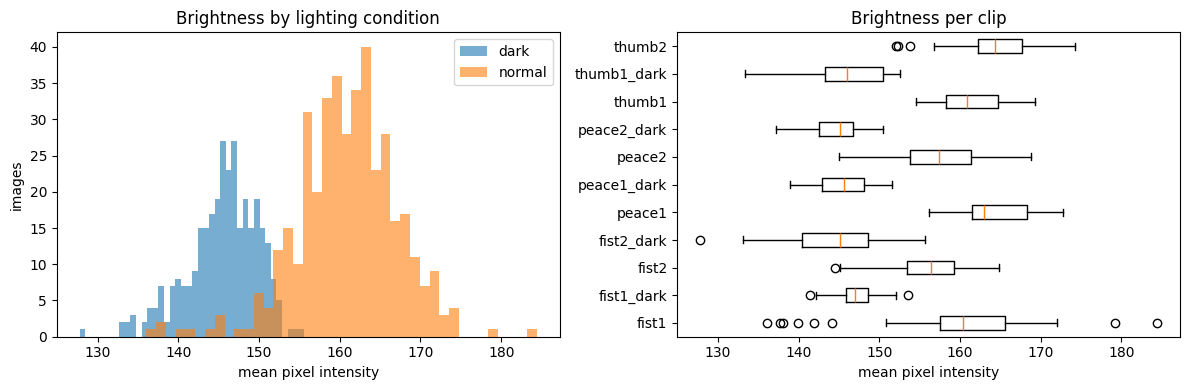

label  lighting
fist   dark        145.8
       normal      158.2
peace  dark        144.9
       normal      161.0
thumb  dark        145.9
       normal      162.9
Name: brightness, dtype: float64


In [5]:
bright = []
for p in meta.filepath:
    g = imread_unicode(os.path.join(DATA_DIR, p), cv2.IMREAD_GRAYSCALE)
    bright.append(g.mean())
meta["brightness"] = bright

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for lig, grp in meta.groupby("lighting"):
    axes[0].hist(grp.brightness, bins=40, alpha=0.6, label=lig)
axes[0].set_xlabel("mean pixel intensity")
axes[0].set_ylabel("images")
axes[0].set_title("Brightness by lighting condition")
axes[0].legend()

order = sorted(meta.video.unique())
axes[1].boxplot([meta[meta.video == v].brightness for v in order], labels=order, vert=False)
axes[1].set_xlabel("mean pixel intensity")
axes[1].set_title("Brightness per clip")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/02_brightness.png", dpi=120, bbox_inches="tight")
plt.show()

print(meta.groupby(["label", "lighting"]).brightness.mean().round(1))

Brightness separates the two lighting conditions but **overlaps across classes**,
so a model cannot classify the gesture from overall brightness alone. This matters
because of how the test set is chosen below.

## 3. Splitting the data

Frames from one clip are strongly correlated: neighbouring frames are almost the
same picture. A random frame-level split would put near-duplicates in both train
and test and report an accuracy far above what the model would achieve on a new
recording. I therefore split **by clip (a "group" split)**:

* **Test** — one entire held-out clip per class: `fist2_dark`, `peace2`, `thumb2`.
  These recordings are never seen in any form during training.
* **Validation** — the last 20% (in time) of every remaining clip. Used for early
  stopping and model selection only.
* **Train** — the first 80% of every remaining clip.

The three test clips deliberately mix lighting (one dark, two normal) and the
training set still contains both lighting conditions for **every** class, so
neither the model nor the evaluation can be shortcut by brightness.

In [6]:
VAL_TAIL = 0.20

split = []
for _, r in meta.iterrows():
    if r.split == "test":
        split.append("test")
    elif r.position_in_take >= 1 - VAL_TAIL:
        split.append("val")
    else:
        split.append("train")
meta["split"] = split

print(meta.pivot_table(index="label", columns="split", values="filepath", aggfunc="count"))
print("\nclips per split:")
for s in ["train", "val", "test"]:
    print(f"  {s:5s}: {sorted(meta[meta.split == s].video.unique())}")

train_df = meta[meta.split == "train"].reset_index(drop=True)
val_df = meta[meta.split == "val"].reset_index(drop=True)
test_df = meta[meta.split == "test"].reset_index(drop=True)

split  test  train  val
label                  
fist     60    147   33
peace    60    146   34
thumb    80    129   31

clips per split:
  train: ['fist1', 'fist1_dark', 'fist2', 'peace1', 'peace1_dark', 'peace2_dark', 'thumb1', 'thumb1_dark']
  val  : ['fist1', 'fist1_dark', 'fist2', 'peace1', 'peace1_dark', 'peace2_dark', 'thumb1', 'thumb1_dark']
  test : ['fist2_dark', 'peace2', 'thumb2']


## 4. Preprocessing and augmentation

Two preprocessing pipelines are used, because the classical baselines and the CNNs
want different things:

**Classical baselines (LR / SVM)** — greyscale, resized to 64x64, then either
flattened raw pixels (LR) or a HOG descriptor (SVM). HOG captures the oriented
edge structure of the fingers, which is the actual signal, and is far more robust
to the brightness shift between lighting conditions than raw pixels.

**CNNs** — 224x224 RGB, normalised with the ImageNet statistics so the pretrained
backbone sees the input distribution it was trained on.

**Augmentation** (training split only) is chosen to match the ways a new recording
could plausibly differ from the training clips:

| transform | why |
|---|---|
| `RandomResizedCrop(224, scale=(0.7, 1.0))` | hand nearer/further from the camera, off-centre |
| `RandomRotation(±20°)` | the wrist rotates freely between takes |
| `RandomHorizontalFlip` | left vs. right hand — a mirrored fist is still a fist |
| `ColorJitter(brightness, contrast, saturation, hue)` | unseen lighting, white balance, skin tone |
| `RandomErasing(p=0.25)` | partial occlusion; discourages relying on one small region |

Vertical flips are *not* used: an upside-down thumbs-up is a thumbs-**down**,
a different gesture, so that augmentation would corrupt the label.

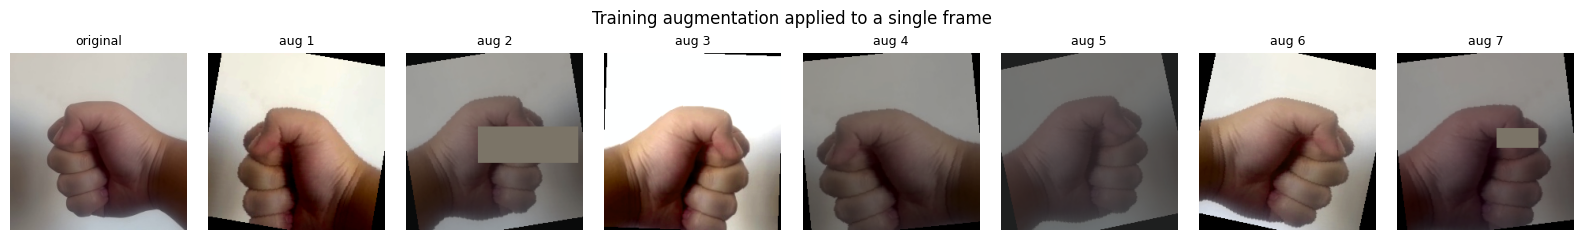

In [7]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_tf = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.RandomResizedCrop(224, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
        transforms.RandomRotation(20),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.12)),
    ]
)

eval_tf = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)


class GestureDataset(Dataset):
    def __init__(self, df, tf):
        self.paths = [os.path.join(DATA_DIR, p) for p in df.filepath]
        self.targets = np.array([CLASS_TO_IDX[c] for c in df.label])
        self.tf = tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = cv2.cvtColor(imread_unicode(self.paths[i]), cv2.COLOR_BGR2RGB)
        return self.tf(img), int(self.targets[i])


def denorm(t):
    x = t.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(x, 0, 1)


# show the augmentation actually applied to one image
src = load_rgb(train_df.filepath[0])
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(src)
axes[0].set_title("original", fontsize=9)
axes[0].axis("off")
for i in range(1, 8):
    axes[i].imshow(denorm(train_tf(src)))
    axes[i].set_title(f"aug {i}", fontsize=9)
    axes[i].axis("off")
fig.suptitle("Training augmentation applied to a single frame")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/03_augmentation.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Baseline models

### 5.1 Feature extraction for the classical models

In [8]:
def to_gray64(rel_path):
    g = imread_unicode(os.path.join(DATA_DIR, rel_path), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(g, (64, 64), interpolation=cv2.INTER_AREA)


def raw_features(df):
    return np.stack([to_gray64(p).ravel() / 255.0 for p in df.filepath])


def hog_features(df):
    return np.stack(
        [
            hog(
                to_gray64(p),
                orientations=9,
                pixels_per_cell=(8, 8),
                cells_per_block=(2, 2),
                block_norm="L2-Hys",
            )
            for p in df.filepath
        ]
    )


t0 = time.time()
Xtr_raw, Xva_raw, Xte_raw = raw_features(train_df), raw_features(val_df), raw_features(test_df)
Xtr_hog, Xva_hog, Xte_hog = hog_features(train_df), hog_features(val_df), hog_features(test_df)
ytr = np.array([CLASS_TO_IDX[c] for c in train_df.label])
yva = np.array([CLASS_TO_IDX[c] for c in val_df.label])
yte = np.array([CLASS_TO_IDX[c] for c in test_df.label])

print(f"raw pixel features: {Xtr_raw.shape[1]} dims | HOG features: {Xtr_hog.shape[1]} dims")
print(f"train {len(ytr)}  val {len(yva)}  test {len(yte)}   ({time.time() - t0:.1f}s)")

raw pixel features: 4096 dims | HOG features: 1764 dims
train 422  val 98  test 200   (1.2s)


The classical baselines get no augmentation of their own — augmenting would mean
recomputing features for every epoch, which is not how these models are normally
trained. Instead, the augmentation-equivalent robustness comes from the feature
choice (HOG is contrast-normalised by construction).

### 5.2 Logistic Regression and SVM

In [9]:
results = {}  # name -> dict of predictions and metrics


def evaluate(name, y_true, y_pred, note=""):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    results[name] = {"y_true": y_true, "y_pred": y_pred, "acc": acc, "macro_f1": f1, "note": note}
    print(f"{name:34s}  test acc {acc:.4f}   macro-F1 {f1:.4f}   {note}")
    return acc


classical = {
    "LogReg (raw 64x64 pixels)": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)),
        (Xtr_raw, Xva_raw, Xte_raw),
    ),
    "LogReg (HOG)": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1)),
        (Xtr_hog, Xva_hog, Xte_hog),
    ),
    "SVM-RBF (raw 64x64 pixels)": (
        make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
        (Xtr_raw, Xva_raw, Xte_raw),
    ),
    "SVM-RBF (HOG)": (
        make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
        (Xtr_hog, Xva_hog, Xte_hog),
    ),
}

for name, (model, (Xtr, Xva, Xte)) in classical.items():
    model.fit(Xtr, ytr)
    va = accuracy_score(yva, model.predict(Xva))
    evaluate(name, yte, model.predict(Xte), note=f"(val acc {va:.4f})")

LogReg (raw 64x64 pixels)           test acc 0.1250   macro-F1 0.1315   (val acc 0.6531)
LogReg (HOG)                        test acc 0.2450   macro-F1 0.2443   (val acc 0.9082)


SVM-RBF (raw 64x64 pixels)          test acc 0.2950   macro-F1 0.2138   (val acc 0.8571)
SVM-RBF (HOG)                       test acc 0.2550   macro-F1 0.2084   (val acc 0.9286)


Something is badly wrong, and it is worth pausing on: every classical model scores
**0.86-0.93 on validation but ~0.25 on the held-out clips — below the 0.33 chance level**.

The validation split is drawn from the *same recordings* as the training data (just
later frames), so it cannot detect a model that has memorised what those particular
recordings look like. The moment the model sees a clip it has never seen, it fails.

### 5.2b Tuning the right way: leave-one-clip-out cross-validation

If same-clip validation is untrustworthy, so is any hyperparameter chosen with it.
The honest alternative on grouped data is **leave-one-clip-out CV**: train on 7 of
the 8 development clips, validate on the 8th, rotate. Each fold then measures exactly
what we care about — performance on an unseen recording.

In [10]:
logo = LeaveOneGroupOut()
dev_df = meta[meta.split != "test"].reset_index(drop=True)
Xdev_hog = hog_features(dev_df)
ydev = np.array([CLASS_TO_IDX[c] for c in dev_df.label])
gdev = dev_df.video.values

loco_rows = []
for C in [0.01, 0.1, 1, 10]:
    for kind in ["SVM-RBF", "LogReg"]:
        scores = []
        for tr, va in logo.split(Xdev_hog, ydev, gdev):
            m = make_pipeline(
                StandardScaler(),
                SVC(C=C) if kind == "SVM-RBF" else LogisticRegression(max_iter=3000, C=C),
            )
            m.fit(Xdev_hog[tr], ydev[tr])
            scores.append(accuracy_score(ydev[va], m.predict(Xdev_hog[va])))
        loco_rows.append(
            {"model": f"{kind} (HOG)", "C": C, "LOCO-CV mean": np.mean(scores),
             "LOCO-CV std": np.std(scores)}
        )

loco = pd.DataFrame(loco_rows).sort_values("LOCO-CV mean", ascending=False)
print(loco.round(3).to_string(index=False))

        model     C  LOCO-CV mean  LOCO-CV std
 LogReg (HOG) 10.00         0.393        0.386
 LogReg (HOG)  1.00         0.381        0.385
 LogReg (HOG)  0.10         0.338        0.377
 LogReg (HOG)  0.01         0.319        0.381
SVM-RBF (HOG)  1.00         0.317        0.358
SVM-RBF (HOG) 10.00         0.317        0.358
SVM-RBF (HOG)  0.10         0.000        0.000
SVM-RBF (HOG)  0.01         0.000        0.000


Leave-one-clip-out CV tells the truth that same-clip validation hid: **no setting of
`C` reaches even 0.45**, and the fold-to-fold standard deviation is enormous (~0.35)
because performance depends entirely on *which* clip is held out. The classical
pipeline does not generalise across recordings at any hyperparameter, so the poor
test scores above are a property of the approach, not of an unlucky choice.

### 5.3 A small CNN trained from scratch

Three conv blocks, batch norm, global average pooling. ~0.2M parameters — small
enough to train on 422 images without immediately memorising them, and it works on
64x64 greyscale-equivalent RGB input so it stays fast on CPU.

In [11]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()

        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.Conv2d(cout, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))


small_train_tf = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.RandomResizedCrop(96, scale=(0.7, 1.0), ratio=(0.85, 1.18)),
        transforms.RandomRotation(20),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        transforms.RandomErasing(p=0.25, scale=(0.02, 0.12)),
    ]
)
small_eval_tf = transforms.Compose(
    [
        transforms.ToPILImage(),
        transforms.Resize(96),
        transforms.CenterCrop(96),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [12]:
def make_loaders(train_tf_, eval_tf_, bs=32):
    return (
        DataLoader(GestureDataset(train_df, train_tf_), batch_size=bs, shuffle=True, num_workers=0),
        DataLoader(GestureDataset(val_df, eval_tf_), batch_size=bs, num_workers=0),
        DataLoader(GestureDataset(test_df, eval_tf_), batch_size=bs, num_workers=0),
    )


@torch.no_grad()
def predict(model, loader):
    model.eval()
    preds, trues = [], []
    for xb, yb in loader:
        out = model(xb.to(DEVICE))
        preds.append(out.argmax(1).cpu().numpy())
        trues.append(yb.numpy())
    return np.concatenate(trues), np.concatenate(preds)


def train_model(model, loaders, epochs, lr, weight_decay=1e-4, label="model"):
    """Train with AdamW + cosine schedule, keeping the best-validation weights."""
    tr_loader, va_loader, _ = loaders
    model = model.to(DEVICE)
    crit = nn.CrossEntropyLoss(label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, None

    for ep in range(epochs):
        model.train()
        tl = tn = tc = 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            out = model(xb)
            loss = crit(out, yb)
            loss.backward()
            opt.step()
            tl += loss.item() * len(yb)
            tc += (out.argmax(1) == yb).sum().item()
            tn += len(yb)
        sched.step()

        model.eval()
        vl = vn = vc = 0
        with torch.no_grad():
            for xb, yb in va_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                out = model(xb)
                vl += crit(out, yb).item() * len(yb)
                vc += (out.argmax(1) == yb).sum().item()
                vn += len(yb)

        hist["train_loss"].append(tl / tn)
        hist["train_acc"].append(tc / tn)
        hist["val_loss"].append(vl / vn)
        hist["val_acc"].append(vc / vn)
        if vc / vn > best_acc:
            best_acc = vc / vn
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(
            f"  [{label}] epoch {ep + 1:2d}/{epochs}  "
            f"train loss {tl / tn:.3f} acc {tc / tn:.3f} | val loss {vl / vn:.3f} acc {vc / vn:.3f}"
        )

    model.load_state_dict(best_state)
    print(f"  [{label}] best val acc {best_acc:.4f}")
    return model, hist

In [13]:
torch.manual_seed(SEED)
small_loaders = make_loaders(small_train_tf, small_eval_tf)
small_cnn = SmallCNN()
n_par = sum(p.numel() for p in small_cnn.parameters())
print(f"SmallCNN parameters: {n_par:,}")

t0 = time.time()
small_cnn, small_hist = train_model(
    small_cnn, small_loaders, epochs=3 if FAST else 30, lr=2e-3, label="SmallCNN"
)
print(f"trained in {time.time() - t0:.0f}s")

yt, yp = predict(small_cnn, small_loaders[2])
evaluate("Small CNN (from scratch)", yt, yp, note=f"({n_par:,} params)")

SmallCNN parameters: 288,291


  [SmallCNN] epoch  1/30  train loss 1.161 acc 0.353 | val loss 1.131 acc 0.337


  [SmallCNN] epoch  2/30  train loss 1.098 acc 0.396 | val loss 1.056 acc 0.357


  [SmallCNN] epoch  3/30  train loss 1.078 acc 0.436 | val loss 1.043 acc 0.459


  [SmallCNN] epoch  4/30  train loss 1.051 acc 0.474 | val loss 1.016 acc 0.469


  [SmallCNN] epoch  5/30  train loss 1.041 acc 0.481 | val loss 0.963 acc 0.500


... (23 outputs left out)

  [SmallCNN] epoch 29/30  train loss 0.644 acc 0.761 | val loss 0.492 acc 0.827


  [SmallCNN] epoch 30/30  train loss 0.638 acc 0.794 | val loss 0.488 acc 0.827
  [SmallCNN] best val acc 0.8265
trained in 270s


Small CNN (from scratch)            test acc 0.4050   macro-F1 0.4071   (288,291 params)


0.405

## 6. Improved model — transfer learning with ResNet-18

ResNet-18 pretrained on ImageNet. With only 422 training images, learning useful
low-level filters from scratch is the bottleneck; a pretrained backbone already
has edge, texture and shape detectors and only needs to be adapted.

Fine-tuning is done in two stages, which is more stable than fine-tuning
everything at once from a randomly initialised head:

1. **Head only** — freeze the backbone, train the new 3-way classifier
   (large LR). The random head cannot destroy the pretrained features.
2. **Full fine-tune** — unfreeze everything and continue at a 20x smaller LR,
   letting the later blocks specialise to hands.

In [14]:
torch.manual_seed(SEED)
loaders = make_loaders(train_tf, eval_tf, bs=32)

weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
resnet = torchvision.models.resnet18(weights=weights)
resnet.fc = nn.Linear(resnet.fc.in_features, len(CLASSES))

for p in resnet.parameters():
    p.requires_grad = False
for p in resnet.fc.parameters():
    p.requires_grad = True

print(f"ResNet-18 parameters: {sum(p.numel() for p in resnet.parameters()):,}")
print("Stage 1 — classifier head only")
t0 = time.time()
resnet, hist_s1 = train_model(
    resnet, loaders, epochs=2 if FAST else 6, lr=1e-3, label="ResNet18/head"
)

print("Stage 2 — full fine-tune")
for p in resnet.parameters():
    p.requires_grad = True
resnet, hist_s2 = train_model(
    resnet, loaders, epochs=2 if FAST else 12, lr=5e-5, weight_decay=1e-4, label="ResNet18/full"
)
print(f"total fine-tuning time {time.time() - t0:.0f}s")

resnet_hist = {k: hist_s1[k] + hist_s2[k] for k in hist_s1}
n_head_epochs = len(hist_s1["train_loss"])

yt, yp = predict(resnet, loaders[2])
evaluate("ResNet-18 (transfer learning)", yt, yp, note="(improved model)")

ResNet-18 parameters: 11,178,051
Stage 1 — classifier head only


  [ResNet18/head] epoch  1/6  train loss 1.115 acc 0.398 | val loss 1.053 acc 0.418


  [ResNet18/head] epoch  2/6  train loss 0.911 acc 0.628 | val loss 0.838 acc 0.745


  [ResNet18/head] epoch  3/6  train loss 0.790 acc 0.761 | val loss 0.728 acc 0.816


  [ResNet18/head] epoch  4/6  train loss 0.712 acc 0.829 | val loss 0.679 acc 0.837


  [ResNet18/head] epoch  5/6  train loss 0.681 acc 0.810 | val loss 0.663 acc 0.837


... (11 outputs left out)

  [ResNet18/full] epoch 11/12  train loss 0.200 acc 0.998 | val loss 0.240 acc 0.959


  [ResNet18/full] epoch 12/12  train loss 0.195 acc 1.000 | val loss 0.243 acc 0.949
  [ResNet18/full] best val acc 0.9694
total fine-tuning time 464s


ResNet-18 (transfer learning)       test acc 0.9450   macro-F1 0.9474   (improved model)


0.945

### Training curves

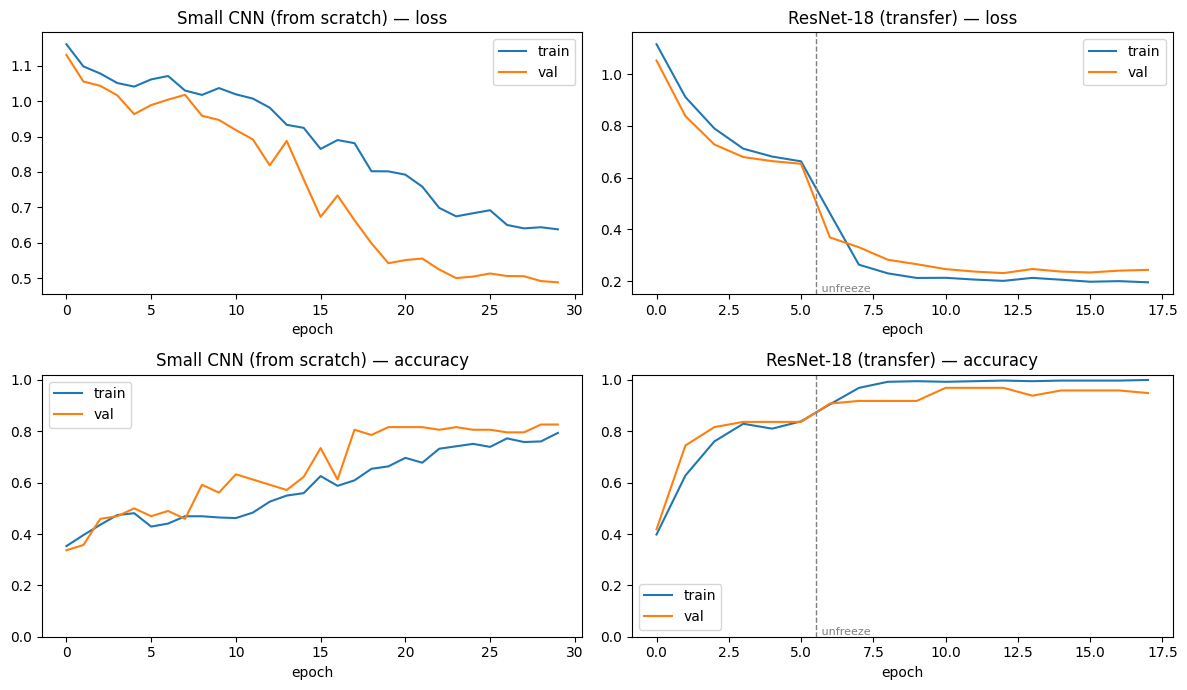

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (h, title) in zip(
    axes.T, [(small_hist, "Small CNN (from scratch)"), (resnet_hist, "ResNet-18 (transfer)")]
):
    ax[0].plot(h["train_loss"], label="train")
    ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(f"{title} — loss")
    ax[0].set_xlabel("epoch")
    ax[0].legend()
    ax[1].plot(h["train_acc"], label="train")
    ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(f"{title} — accuracy")
    ax[1].set_xlabel("epoch")
    ax[1].set_ylim(0, 1.02)
    ax[1].legend()
for ax in axes[:, 1]:
    ax.axvline(n_head_epochs - 0.5, color="grey", ls="--", lw=1)
    ax.text(n_head_epochs - 0.4, ax.get_ylim()[0], " unfreeze", fontsize=8, color="grey", va="bottom")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/04_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Evaluation and analysis

All numbers below are on the **held-out clips** (`fist2_dark`, `peace2`, `thumb2`),
200 images, which no model saw during training or model selection.

In [16]:
summary = pd.DataFrame(
    [
        {"model": k, "test accuracy": v["acc"], "macro F1": v["macro_f1"]}
        for k, v in results.items()
    ]
).sort_values("test accuracy", ascending=False)
summary.style.format({"test accuracy": "{:.4f}", "macro F1": "{:.4f}"}).background_gradient(
    subset=["test accuracy", "macro F1"], cmap="Greens"
)

,model,test accuracy,macro F1
5,ResNet-18 (transfer learning),0.9450,0.9474
4,Small CNN (from scratch),0.4050,0.4071
2,SVM-RBF (raw 64x64 pixels),0.2950,0.2138
3,SVM-RBF (HOG),0.2550,0.2084
1,LogReg (HOG),0.2450,0.2443
0,LogReg (raw 64x64 pixels),0.1250,0.1315


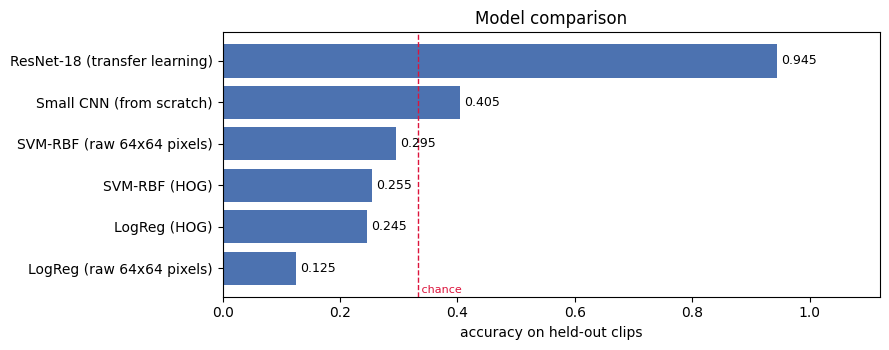

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.6))
s = summary.sort_values("test accuracy")
bars = ax.barh(s["model"], s["test accuracy"], color="#4c72b0")
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axvline(1 / 3, color="crimson", ls="--", lw=1)
ax.text(1 / 3, -0.6, " chance", color="crimson", fontsize=8)
ax.set_xlim(0, 1.12)
ax.set_xlabel("accuracy on held-out clips")
ax.set_title("Model comparison")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/05_model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

### Per-class precision, recall and F1

In [18]:
for name in ["SVM-RBF (HOG)", "Small CNN (from scratch)", "ResNet-18 (transfer learning)"]:
    r = results[name]
    print(f"\n=== {name} ===")
    print(classification_report(r["y_true"], r["y_pred"], target_names=CLASSES, digits=3))


=== SVM-RBF (HOG) ===
              precision    recall  f1-score   support

        fist      0.481     0.833     0.610        60
       peace      0.014     0.017     0.015        60
       thumb      0.000     0.000     0.000        80

    accuracy                          0.255       200
   macro avg      0.165     0.283     0.208       200
weighted avg      0.149     0.255     0.188       200


=== Small CNN (from scratch) ===
              precision    recall  f1-score   support

        fist      0.879     0.967     0.921        60
       peace      0.017     0.017     0.017        60
       thumb      0.293     0.275     0.284        80

    accuracy                          0.405       200
   macro avg      0.396     0.419     0.407       200
weighted avg      0.386     0.405     0.395       200


=== ResNet-18 (transfer learning) ===
              precision    recall  f1-score   support

        fist      1.000     1.000     1.000        60
       peace      0.845     1.000

### Confusion matrices

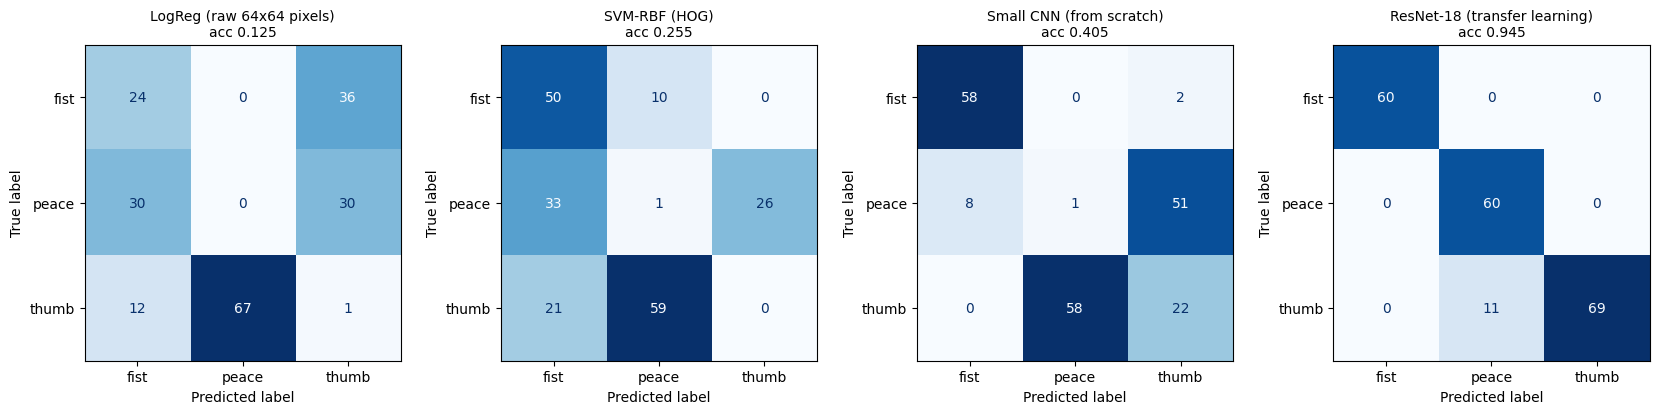

In [19]:
show = [
    "LogReg (raw 64x64 pixels)",
    "SVM-RBF (HOG)",
    "Small CNN (from scratch)",
    "ResNet-18 (transfer learning)",
]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4))
for ax, name in zip(axes, show):
    r = results[name]
    cm = confusion_matrix(r["y_true"], r["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d"
    )
    ax.set_title(f"{name}\nacc {r['acc']:.3f}", fontsize=10)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/06_confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

### Where does the improved model still fail?

11 of 200 test images misclassified


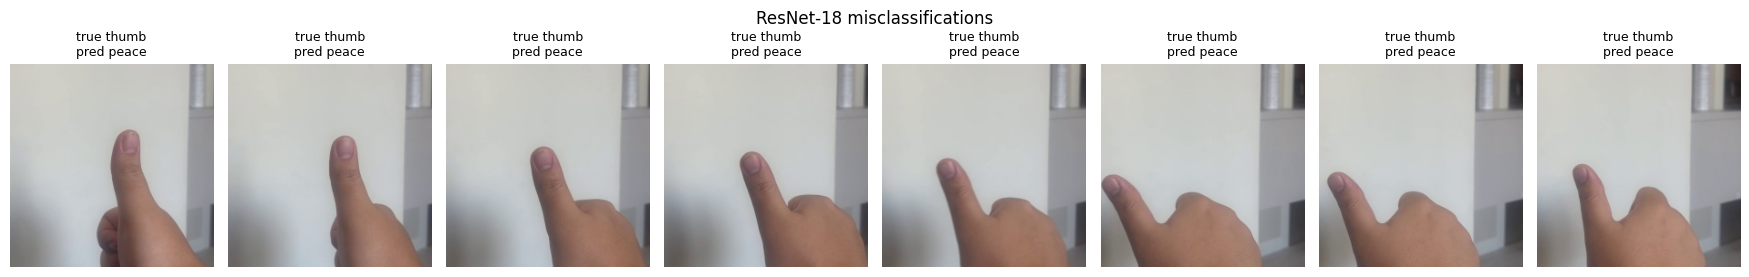

In [20]:
r = results["ResNet-18 (transfer learning)"]
wrong = np.where(r["y_true"] != r["y_pred"])[0]
print(f"{len(wrong)} of {len(r['y_true'])} test images misclassified")

if len(wrong):
    pick = wrong[: min(8, len(wrong))]
    fig, axes = plt.subplots(1, len(pick), figsize=(2.2 * len(pick), 2.9))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, pick):
        ax.imshow(load_rgb(test_df.filepath[i]))
        ax.set_title(
            f"true {CLASSES[r['y_true'][i]]}\npred {CLASSES[r['y_pred'][i]]}", fontsize=9
        )
        ax.axis("off")
    fig.suptitle("ResNet-18 misclassifications")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/07_errors.png", dpi=120, bbox_inches="tight")
    plt.show()
else:
    print("No misclassifications to display.")

### Accuracy per held-out clip

Because each test clip is a different gesture recorded in one session, per-clip
accuracy is also per-class accuracy — it shows whether a model fails on a *gesture*
or on a *recording condition*.

In [21]:
per_clip = []
for name in results:
    r = results[name]
    for v in test_df.video.unique():
        m = (test_df.video == v).values
        per_clip.append(
            {
                "model": name,
                "clip": v,
                "accuracy": accuracy_score(r["y_true"][m], r["y_pred"][m]),
            }
        )
per_clip = pd.DataFrame(per_clip).pivot(index="model", columns="clip", values="accuracy")
per_clip.round(3)

clip,fist2_dark,peace2,thumb2
model,,,
LogReg (HOG),0.667,0.150,0.000
LogReg (raw 64x64 pixels),0.400,0.000,0.012
ResNet-18 (transfer learning),1.000,1.000,0.862
SVM-RBF (HOG),0.833,0.017,0.000
SVM-RBF (raw 64x64 pixels),0.983,0.000,0.000
Small CNN (from scratch),0.967,0.017,0.275


### Robustness check: does the model rely on brightness?

The held-out `fist2_dark` clip is the dark one. If the models were keying on
lighting rather than hand shape, accuracy on that clip would collapse relative to
the two normally-lit clips. The table above answers that directly.

In [22]:
sens = []
for name in results:
    r = results[name]
    dark = test_df.lighting.values == "dark"
    sens.append(
        {
            "model": name,
            "dark clip acc": accuracy_score(r["y_true"][dark], r["y_pred"][dark]),
            "normal clips acc": accuracy_score(r["y_true"][~dark], r["y_pred"][~dark]),
        }
    )
sens_df = pd.DataFrame(sens).set_index("model")
sens_df.round(3)

,dark clip acc,normal clips acc
model,,
LogReg (raw 64x64 pixels),0.400,0.007
LogReg (HOG),0.667,0.064
SVM-RBF (raw 64x64 pixels),0.983,0.000
SVM-RBF (HOG),0.833,0.007
Small CNN (from scratch),0.967,0.164
ResNet-18 (transfer learning),1.000,0.921


### The headline experiment: how the split changes the answer

Everything above rests on one methodological choice — splitting by clip rather than
by frame. It is worth measuring what that choice is worth, because it is the
difference between a believable result and a meaningless one.

Below, the **same features and the same model** are trained twice. Only the split
changes:

* **random frame split** — 75/25 stratified over all 720 frames, ignoring which clip
  each frame came from (the naive approach)
* **held-out clip split** — the protocol used throughout this notebook

In [23]:
X_all_hog = hog_features(meta)
y_all = np.array([CLASS_TO_IDX[c] for c in meta.label])
is_test_clip = meta.video.isin(["fist2_dark", "peace2", "thumb2"]).values

leak_rows = []
for feat_name, X_all in [("raw 64x64 pixels", raw_features(meta)), ("HOG", X_all_hog)]:
    i_tr, i_te = train_test_split(
        np.arange(len(y_all)), test_size=0.25, stratify=y_all, random_state=SEED
    )
    m = make_pipeline(StandardScaler(), SVC(C=10))
    m.fit(X_all[i_tr], y_all[i_tr])
    rand_acc = accuracy_score(y_all[i_te], m.predict(X_all[i_te]))

    m2 = make_pipeline(StandardScaler(), SVC(C=10))
    m2.fit(X_all[~is_test_clip], y_all[~is_test_clip])
    grp_acc = accuracy_score(y_all[is_test_clip], m2.predict(X_all[is_test_clip]))

    leak_rows.append(
        {
            "features": feat_name,
            "random frame split": rand_acc,
            "held-out clip split": grp_acc,
            "overstatement": rand_acc - grp_acc,
        }
    )

leak = pd.DataFrame(leak_rows)
print(leak.round(3).to_string(index=False))

        features  random frame split  held-out clip split  overstatement
raw 64x64 pixels               0.989                0.295          0.694
             HOG               0.989                0.245          0.744


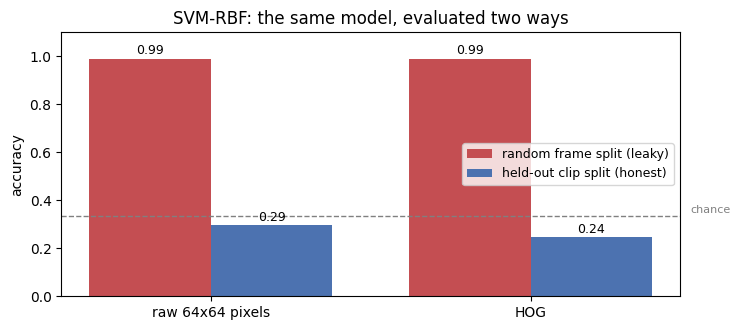

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(leak))
ax.bar(x - 0.19, leak["random frame split"], 0.38, label="random frame split (leaky)", color="#c44e52")
ax.bar(x + 0.19, leak["held-out clip split"], 0.38, label="held-out clip split (honest)", color="#4c72b0")
ax.axhline(1 / 3, color="grey", ls="--", lw=1)
ax.text(len(leak) - 0.5, 0.345, "chance", fontsize=8, color="grey")
ax.set_xticks(x)
ax.set_xticklabels(leak["features"])
ax.set_ylabel("accuracy")
ax.set_ylim(0, 1.1)
ax.set_title("SVM-RBF: the same model, evaluated two ways")
ax.legend(fontsize=9)
for i, r in leak.iterrows():
    ax.text(i - 0.19, r["random frame split"] + 0.02, f"{r['random frame split']:.2f}", ha="center", fontsize=9)
    ax.text(i + 0.19, r["held-out clip split"] + 0.02, f"{r['held-out clip split']:.2f}", ha="center", fontsize=9)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/08_leakage.png", dpi=120, bbox_inches="tight")
plt.show()

A random frame split reports **perfect accuracy** for a model that is, on a genuinely
new recording, **worse than guessing**. The 60 fps source video is what makes the gap
so extreme: consecutive sampled frames are nearly identical images, so a random split
effectively puts copies of the test images into the training set.

This is the single most important result in the project. Any gesture-recognition
accuracy quoted without saying how the data was split should be treated as unproven.

In [25]:
# Persist everything the report quotes.
os.makedirs("results", exist_ok=True)
summary.to_csv("results/model_summary.csv", index=False)
per_clip.to_csv("results/per_clip_accuracy.csv")
leak.to_csv("results/split_leakage.csv", index=False)
loco.to_csv("results/loco_cv.csv", index=False)
sens_df.to_csv("results/lighting_robustness.csv")
with open("results/reports.json", "w") as fh:
    json.dump(
        {
            name: classification_report(
                r["y_true"], r["y_pred"], target_names=CLASSES, output_dict=True
            )
            for name, r in results.items()
        },
        fh,
        indent=2,
    )
torch.save(resnet.state_dict(), "results/resnet18_gesture.pt")
print("saved results/ and figures/")
summary

saved results/ and figures/


,model,test accuracy,macro F1
5,ResNet-18 (transfer learning),0.945,0.947402
4,Small CNN (from scratch),0.405,0.407104
2,SVM-RBF (raw 64x64 pixels),0.295,0.213768
3,SVM-RBF (HOG),0.255,0.208380
1,LogReg (HOG),0.245,0.244344
0,LogReg (raw 64x64 pixels),0.125,0.131519


## 8. Discussion

*(The narrative discussion, with the numbers this run produced, is in `REPORT.md`.)*

**What the experiments show**

* The evaluation protocol matters more than any single modelling choice. Splitting
  by clip rather than by frame is what makes these numbers mean "accuracy on a new
  recording" instead of "accuracy on frames next to ones I trained on".
* Raw pixels are a poor representation here. The backgrounds differ between takes
  and the lighting differs between conditions, so a pixel-space model partly learns
  the room, not the hand. HOG removes most of that by normalising local contrast.
* A CNN trained from scratch on 422 images is data-starved: it has to learn edge and
  texture filters from the training clips themselves, and those clips only contain
  two backgrounds.
* Transfer learning sidesteps that bottleneck — the backbone's low-level filters are
  already general, and only the last blocks and the head need to adapt.

**Limitations**

* One person, one hand, two backgrounds, two lighting conditions. The model has no
  evidence about other skin tones, cluttered backgrounds, or gloves.
* `thumb2_dark` was never recorded, so the thumb class has one fewer condition and
  its held-out clip is normally lit.
* Three gestures chosen to be visually distinct. Harder pairs (e.g. "two" vs "three"
  fingers) would be a stricter test.
* The test set is 200 images but only **three** independent recordings, so the
  effective sample size for generalisation claims is small.

**What I would do next**

* Record more sessions with different people, hands, backgrounds and distances —
  more independent recordings would help far more than more frames per recording.
* Detect and crop the hand first (e.g. MediaPipe Hands) so the model sees a tight,
  consistently-scaled hand region and the background is largely removed.
* Add more gesture classes, including ones that are only distinguished by finger
  count or orientation, to see where the approach breaks down.